In [138]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score

In [139]:
df = pd.read_csv('RTA Dataset.csv')

In [140]:
df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [141]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allignment              12

In [142]:
df.isnull().sum()

Time                              0
Day_of_week                       0
Age_band_of_driver                0
Sex_of_driver                     0
Educational_level               741
Vehicle_driver_relation         579
Driving_experience              829
Type_of_vehicle                 950
Owner_of_vehicle                482
Service_year_of_vehicle        3928
Defect_of_vehicle              4427
Area_accident_occured           239
Lanes_or_Medians                385
Road_allignment                 142
Types_of_Junction               887
Road_surface_type               172
Road_surface_conditions           0
Light_conditions                  0
Weather_conditions                0
Type_of_collision               155
Number_of_vehicles_involved       0
Number_of_casualties              0
Vehicle_movement                308
Casualty_class                    0
Sex_of_casualty                   0
Age_band_of_casualty              0
Casualty_severity                 0
Work_of_casuality           

In [143]:
df['Accident_severity'].value_counts(normalize=True)

Accident_severity
Slight Injury     0.845648
Serious Injury    0.141523
Fatal injury      0.012829
Name: proportion, dtype: float64

In [144]:
df.drop([ 
    'Number_of_casualties',  
    'Casualty_class', 
    'Sex_of_casualty', 
    'Age_band_of_casualty', 
    'Casualty_severity', 
    'Work_of_casuality', 
    'Fitness_of_casuality',  
    'Cause_of_accident',
    'Service_year_of_vehicle',
    'Defect_of_vehicle'
    ], 
        axis=1,inplace=True)

In [145]:
df.duplicated().sum()

np.int64(1)

In [146]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [147]:
df['hour'] = pd.to_datetime(df['time'], format='%H:%M:%S').dt.hour
df.drop('time', axis=1, inplace=True)

In [148]:
cat_cols = df.select_dtypes('object').columns.tolist()
cat_cols = cat_cols + ['hour']
num_cols = ['number_of_vehicles_involved']


In [149]:
def clean(df, columns):
    for col in columns:
        if df[col].dtype == 'object':
            df[col] = (df[col].str.replace(r'\s+', ' ', regex=True).str.strip())
        
    return df

In [150]:
df = clean(df, cat_cols)

In [151]:
df['area_accident_occured'] = df['area_accident_occured'].replace('Rural village areasOffice areas', 'Unknown')

In [152]:
df['pedestrian_movement'] = df['pedestrian_movement'].str.replace('statioNot a Pedestrianry', 'stationary', regex=False)

In [153]:
df['area_accident_occured'].value_counts()

area_accident_occured
Other                  3819
Office areas           3451
Residential areas      2060
Church areas           1060
Industrial areas        456
School areas            415
Recreational areas      328
Outside rural areas     218
Hospital areas          121
Market areas             63
Rural village areas      44
Unknown                  42
Name: count, dtype: int64

In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   day_of_week                  12316 non-null  object
 1   age_band_of_driver           12316 non-null  object
 2   sex_of_driver                12316 non-null  object
 3   educational_level            11575 non-null  object
 4   vehicle_driver_relation      11737 non-null  object
 5   driving_experience           11487 non-null  object
 6   type_of_vehicle              11366 non-null  object
 7   owner_of_vehicle             11834 non-null  object
 8   area_accident_occured        12077 non-null  object
 9   lanes_or_medians             11931 non-null  object
 10  road_allignment              12174 non-null  object
 11  types_of_junction            11429 non-null  object
 12  road_surface_type            12144 non-null  object
 13  road_surface_conditions      12

In [155]:
for col in df.columns:
    print(col)
    print(df[col].unique())
    print(df[col].nunique())
    print()

day_of_week
['Monday' 'Sunday' 'Friday' 'Wednesday' 'Saturday' 'Thursday' 'Tuesday']
7

age_band_of_driver
['18-30' '31-50' 'Under 18' 'Over 51' 'Unknown']
5

sex_of_driver
['Male' 'Female' 'Unknown']
3

educational_level
['Above high school' 'Junior high school' nan 'Elementary school'
 'High school' 'Unknown' 'Illiterate' 'Writing & reading']
7

vehicle_driver_relation
['Employee' 'Unknown' 'Owner' nan 'Other']
4

driving_experience
['1-2yr' 'Above 10yr' '5-10yr' '2-5yr' nan 'No Licence' 'Below 1yr'
 'unknown']
7

type_of_vehicle
['Automobile' 'Public (> 45 seats)' 'Lorry (41?100Q)' nan
 'Public (13?45 seats)' 'Lorry (11?40Q)' 'Long lorry' 'Public (12 seats)'
 'Taxi' 'Pick up upto 10Q' 'Stationwagen' 'Ridden horse' 'Other' 'Bajaj'
 'Turbo' 'Motorcycle' 'Special vehicle' 'Bicycle']
17

owner_of_vehicle
['Owner' 'Governmental' nan 'Organization' 'Other']
4

area_accident_occured
['Residential areas' 'Office areas' 'Recreational areas'
 'Industrial areas' nan 'Other' 'Church areas' 'Mar

In [156]:
df['fatality'] = (df['accident_severity'] != 'Slight Injury').astype(int)
df = df.drop(columns='accident_severity')

In [168]:
cat_cols = df.select_dtypes('object').columns.tolist()
cat_cols = cat_cols + ['hour']

num_cols = ['number_of_vehicles_involved']

In [169]:
df['fatality'].value_counts(normalize=True)

fatality
0    0.845648
1    0.154352
Name: proportion, dtype: float64

In [170]:
df = df.fillna('Unknown')

In [171]:
df.isnull().sum()

day_of_week                    0
age_band_of_driver             0
sex_of_driver                  0
educational_level              0
vehicle_driver_relation        0
driving_experience             0
type_of_vehicle                0
owner_of_vehicle               0
area_accident_occured          0
lanes_or_medians               0
road_allignment                0
types_of_junction              0
road_surface_type              0
road_surface_conditions        0
light_conditions               0
weather_conditions             0
type_of_collision              0
number_of_vehicles_involved    0
vehicle_movement               0
pedestrian_movement            0
hour                           0
fatality                       0
dtype: int64

In [172]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [173]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [174]:
y_train = df_train.fatality.values
y_val = df_val.fatality.values
y_test = df_test.fatality.values


In [175]:
del df_train['fatality']
del df_val['fatality']
del df_test['fatality']

In [176]:
df_train.shape, df_val.shape, df_test.shape

((7389, 21), (2463, 21), (2464, 21))

In [177]:
df_full_train.fatality.mean()

np.float64(0.15235485180673974)

In [180]:
df_full_train[cat_cols].nunique()

day_of_week                 7
age_band_of_driver          5
sex_of_driver               3
educational_level           7
vehicle_driver_relation     4
driving_experience          8
type_of_vehicle            18
owner_of_vehicle            5
area_accident_occured      12
lanes_or_medians            7
road_allignment            10
types_of_junction           8
road_surface_type           6
road_surface_conditions     4
light_conditions            4
weather_conditions          9
type_of_collision          10
vehicle_movement           13
pedestrian_movement         9
hour                       24
dtype: int64

In [181]:
def mutual_info_fatality_score(series):
    return mutual_info_score(series, df_full_train.fatality)

In [182]:
mi = df_full_train[cat_cols].apply(mutual_info_fatality_score)
mi.sort_values(ascending=False)

hour                       0.003427
age_band_of_driver         0.002338
type_of_vehicle            0.001894
types_of_junction          0.001843
weather_conditions         0.001418
light_conditions           0.001116
area_accident_occured      0.000795
type_of_collision          0.000733
day_of_week                0.000542
pedestrian_movement        0.000411
road_surface_conditions    0.000356
lanes_or_medians           0.000291
driving_experience         0.000288
vehicle_movement           0.000283
owner_of_vehicle           0.000234
sex_of_driver              0.000209
road_surface_type          0.000161
vehicle_driver_relation    0.000120
educational_level          0.000062
road_allignment            0.000037
dtype: float64

In [183]:
df_full_train['number_of_vehicles_involved'].corr(df_full_train.fatality)

np.float64(-0.09370749422501795)

In [184]:
df_full_train['hour'].corr(df_full_train.fatality)

np.float64(0.025768051420288204)

In [185]:
fatality_rate_hour_bin_1 = df_full_train[df_full_train.hour <= 8].fatality.mean()
occurences_bin_1 = df_full_train[df_full_train.hour <= 8].shape[0]

print(f'Fatality rate from 12am - 8am: {fatality_rate_hour_bin_1}')
print(f'Occurences: {occurences_bin_1}')

Fatality rate from 12am - 8am: 0.1458100558659218
Occurences: 1790


In [186]:
fatality_rate_hour_bin_2 = df_full_train[(df_full_train.hour > 8) & (df_full_train.hour <= 16)].fatality.mean()
occurences_bin_2 = df_full_train[(df_full_train.hour > 8) & (df_full_train.hour <= 16)].shape[0]

print(f'Fatality rate from 9pm - 16pm: {fatality_rate_hour_bin_2}')
print(f'Occurences: {occurences_bin_2}')

Fatality rate from 9pm - 16pm: 0.14616595457611872
Occurences: 4447


In [187]:
fatality_rate_hour_bin_3 = df_full_train[df_full_train.hour > 16].fatality.mean()
occurences_bin_3 = df_full_train[df_full_train.hour > 16].shape[0]

print(f'Fatality rate from 17pm - 23pm: {fatality_rate_hour_bin_3}')
print(f'Occurences: {occurences_bin_3}')

Fatality rate from 17pm - 23pm: 0.1632088520055325
Occurences: 3615


In [188]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [309]:
def train(df_train, y_train, model_type='lr', C=0.01):
    train_dicts = df_train[cat_cols + num_cols].to_dict(orient='records')
    dv = DictVectorizer(sparse=True)
    
    X_train = dv.fit_transform(train_dicts)

    if model_type == 'lr':
        model = LogisticRegression(solver='lbfgs', max_iter=2000, C=C, class_weight='balanced')
        model.fit(X_train, y_train)

    elif model_type == 'dt':
        model = DecisionTreeClassifier(class_weight='balanced', max_depth=6, min_samples_leaf=100, random_state=1)
        model.fit(X_train, y_train)

    elif model_type == 'rf':
        model = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=1, class_weight='balanced', random_state=1)
        model.fit(X_train, y_train)

    elif model_type == 'xgb':

        features = list(dv.get_feature_names_out())
        dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
        
        xgb_params = {
        'eta': 0.1,
        'max_depth': 12,
        'min_child_weight': 1,
    
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
    
        'seed': 1,
        'verbosity': 1,
        }

        model = xgb.train(xgb_params, dtrain, num_boost_round=125)

    return dv, model

In [221]:
def predict(df, dv, model, model_type='lr'):
    val_dicts = df[cat_cols + num_cols].to_dict(orient='records')
    X_val = dv.transform(val_dicts)
    features = list(dv.get_feature_names_out())
    
    if model_type == 'xgb':
        dval = xgb.DMatrix(X_val, label=y_train, feature_names=features)
        model.predict(dval)
        y_pred = model.predict(dval)
        
    else: 
        y_pred = model.predict_proba(X_val)[:, 1]

    return y_pred

In [226]:
dv, model = train(df_train, y_train, model_type='dt')
y_pred = predict(df_val, dv, model)

In [227]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.160
0.05 0.160
0.10 0.160
0.15 0.160
0.20 0.160
0.25 0.160
0.30 0.225
0.35 0.225
0.40 0.318
0.45 0.684
0.50 0.684
0.55 0.721
0.60 0.759
0.65 0.795
0.70 0.817
0.75 0.839
0.80 0.839
0.85 0.840
0.90 0.840
0.95 0.840
1.00 0.840


In [209]:
from sklearn.model_selection import KFold

c_values = [0.001, 0.01, 0.1, 0.5, 1, 5, 10]

for C in c_values:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_fold_train = df_fold_train.fatality.values
        y_fold_val = df_fold_val.fatality.values

        dv, model = train(df_fold_train, y_fold_train, C=C)
        y_fold_pred = predict(df_fold_val, dv, model)

        auc = roc_auc_score(y_fold_val, y_fold_pred)
        scores.append(auc)

    print(f'C = {C}, {round(np.mean(scores), 3)}, {round(np.std(scores), 3)}')

C = 0.001, 0.592, 0.024
C = 0.01, 0.593, 0.021
C = 0.1, 0.584, 0.022
C = 0.5, 0.58, 0.021
C = 1, 0.579, 0.021
C = 5, 0.578, 0.021
C = 10, 0.578, 0.021


In [210]:
train_dicts = df_train[cat_cols + num_cols].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=2)

In [211]:
val_dicts = df_val[cat_cols + num_cols].to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [212]:
y_pred_dt = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred_dt)
print('train:', auc)

y_pred_dt = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_dt)
print('val:', auc)

train: 0.591478441580553
val: 0.5803252263900509


In [213]:
scores = []

depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]
leafs = [1, 5, 10, 15, 20, 500, 100, 200]

for depth in depths:
    for leaf in leafs:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf)
        dt.fit(X_train, y_train)
        
        y_pred_dt = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred_dt)
        
        scores.append((depth, leaf, auc))

In [214]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores_dt = pd.DataFrame(scores, columns=columns)

In [215]:
df_scores_pivot_dt = df_scores_dt.pivot(values='auc', columns='max_depth', index='min_samples_leaf')
df_scores_pivot_dt.round(3)

max_depth,NaN,1.0,2.0,3.0,4.0,5.0,6.0,10.0,15.0,20.0
min_samples_leaf,,,,,,,,,,
1,0.535,0.579,0.580,0.581,0.589,0.592,0.589,0.591,0.552,0.528
5,0.551,0.579,0.580,0.581,0.588,0.600,0.584,0.573,0.551,0.541
10,0.586,0.579,0.580,0.582,0.588,0.588,0.591,0.579,0.589,0.584
15,0.580,0.579,0.580,0.581,0.588,0.593,0.595,0.588,0.582,0.582
20,0.578,0.579,0.580,0.580,0.585,0.591,0.593,0.586,0.572,0.585
100,0.603,0.579,0.581,0.581,0.587,0.604,0.610,0.594,0.602,0.603
200,0.600,0.579,0.581,0.582,0.590,0.604,0.607,0.601,0.600,0.600
500,0.599,0.579,0.585,0.586,0.594,0.595,0.596,0.599,0.599,0.599


<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

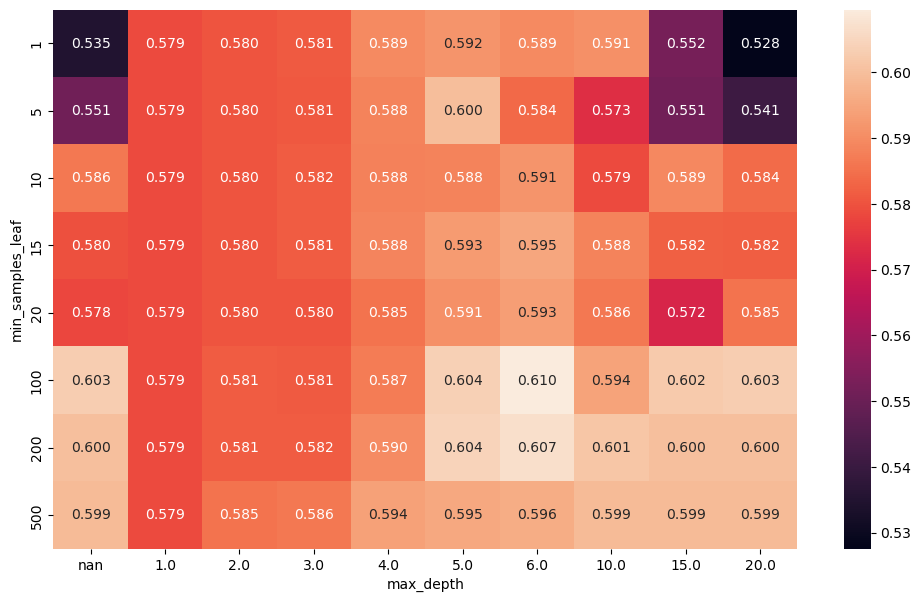

In [216]:
plt.figure(figsize=(12, 7))
sns.heatmap(df_scores_pivot_dt, annot=True, fmt=".3f")

In [228]:
dv, model = train(df_train, y_train, model_type='dt')
y_pred = predict(df_val, dv, model)

roc_auc_score(y_val, y_pred)

np.float64(0.6054170459257151)

In [232]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred_rf = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred_rf)

    scores.append((n, auc))

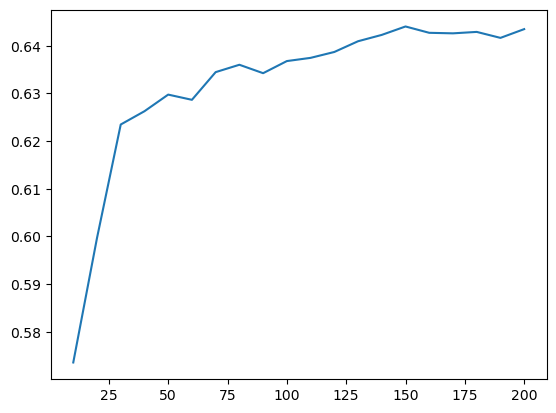

In [233]:
# df_scores_rf = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
# plt.plot(df_scores_rf.n_estimators, df_scores_rf.auc)

In [234]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for depth in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=depth, random_state=1)
        rf.fit(X_train, y_train)
            
        y_pred_rf = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred_rf)
            
        scores.append((n, depth, auc))

columns = ['n_estimators', 'max_depth',  'auc']
df_scores_rf = pd.DataFrame(scores, columns=columns)

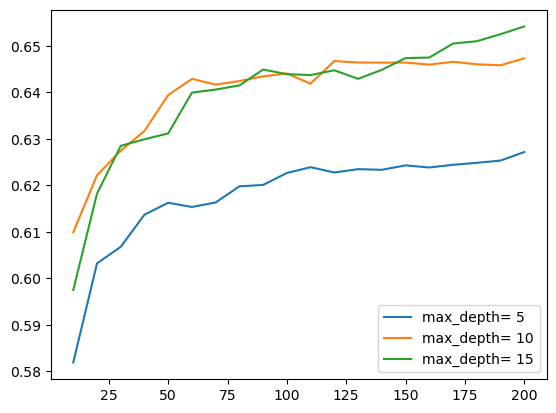

In [235]:
for depth in [5, 10, 15]:
    df_subset = df_scores_rf[df_scores_rf.max_depth == depth]

    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'max_depth= {depth}')
    
plt.legend()

In [236]:
scores = []
leaf = [1, 3, 5, 10, 50]
n_values = range(10, 201, 10)

for leaf in leafs:
    for n in n_values:
        rf = RandomForestClassifier(n_estimators=n, max_depth=15, min_samples_leaf=leaf, random_state=1)
        rf.fit(X_train, y_train)
            
        y_pred_rf = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred_rf)
            
        scores.append((leaf, n, auc))

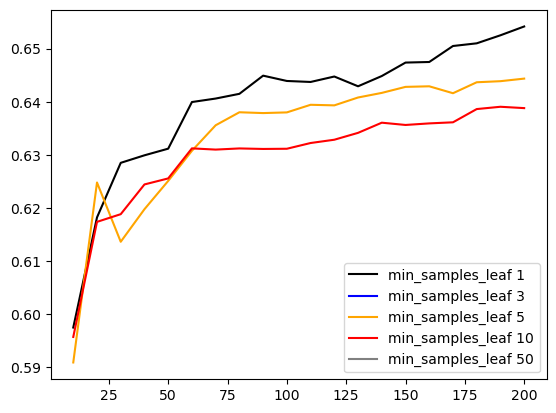

In [237]:
# columns = ['min_samples_leaf', 'n_estimators', 'auc']
# df_scores_rf = pd.DataFrame(scores, columns=columns)

# colors = ['black', 'blue', 'orange', 'red', 'grey']
# values = [1, 3, 5, 10, 50]

# for leaf, col in zip(values, colors):
#     df_subset = df_scores_rf[df_scores_rf.min_samples_leaf == leaf]

#     plt.plot(df_subset.n_estimators, df_subset.auc, color=col, label= f'min_samples_leaf {leaf}')
# plt.legend()

In [240]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=1,
    random_state=1,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print('val:', auc)

val: 0.6541611362314859


In [241]:
import xgboost as xgb

In [242]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [243]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=10)

In [244]:
y_pred_xgb = xgb_model.predict(dval)
roc_auc_score(y_val, y_pred_xgb)

np.float64(0.626856324814214)

In [245]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [246]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [247]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

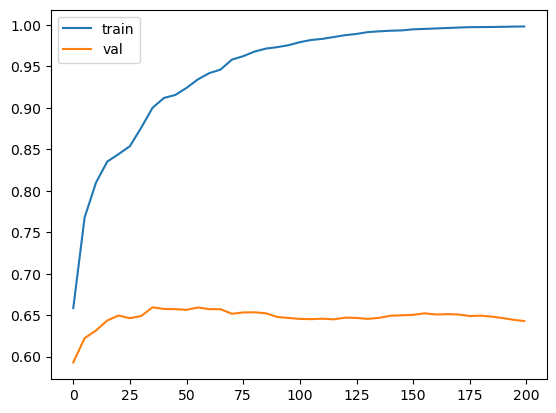

In [248]:
df_score_xgb = parse_xgb_output(output)

plt.plot(df_score_xgb.num_iter, df_score_xgb.train_auc, label='train')
plt.plot(df_score_xgb.num_iter, df_score_xgb.val_auc, label='val')

plt.legend()

In [289]:
scores = {}

In [294]:
%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 12,
    'min_child_weight': 30,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [295]:
key = f'min_child_weight= {xgb_params['min_child_weight']}'
scores[key] = parse_xgb_output(output)
key

'min_child_weight= 30'

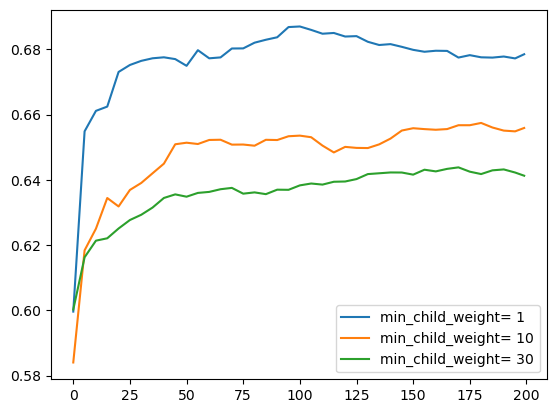

In [296]:
for key, df_score_xgb in scores.items():
    plt.plot(df_score_xgb.num_iter, df_score_xgb.val_auc, label=key)

plt.legend()

In [326]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 12,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=100)

In [327]:
y_pred_xgb = xgb_model.predict(dval)
roc_auc_score(y_val, y_pred_xgb)

np.float64(0.6870689634022175)

In [310]:
dv, model = train(df_train, y_train, model_type='lr')

y_pred_lr = predict(df_val, dv, model, model_type='lr')
lr_score = roc_auc_score(y_val, y_pred_lr)

In [311]:
dv, model = train(df_train, y_train, model_type='dt')

y_pred_dt = predict(df_val, dv, model, model_type='dt')
dt_score = roc_auc_score(y_val, y_pred_dt)

In [312]:
dv, model = train(df_train, y_train, model_type='rf')

y_pred_rf = predict(df_val, dv, model, model_type='rf')
rf_score = roc_auc_score(y_val, y_pred_rf)

In [313]:
dv, model = train(df_train, y_train, model_type='xgb')

y_pred_xgb = predict(df_val, dv, model, model_type='xgb')

xgb_score = roc_auc_score(y_val, y_pred_xgb)

In [314]:
model_scores = pd.Series(
    {'Logistic Regression': lr_score,
     'Decision Tree': dt_score,
     'Random Forest': rf_score,
     'XGBoost': xgb_score}
)
model_scores.sort_values(ascending=False)

XGBoost                0.684438
Random Forest          0.644060
Decision Tree          0.605417
Logistic Regression    0.589539
dtype: float64

In [317]:
df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train.fatality.values

del df_full_train['fatality']

In [319]:
dv = DictVectorizer(sparse=True)

dicts_full_train = df_full_train.to_dict(orient='records')
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [328]:
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test, feature_names=features)

In [330]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 12,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params, dfulltrain, num_boost_round=100)

In [331]:
y_pred_xgb = xgb_model.predict(dtest)
roc_auc_score(y_test, y_pred_xgb)

np.float64(0.6789595445736433)